# Milestone 04 - Advanced Models, Fairness Audit and Bias Mitigation (ASER 2025, Pakistan)

**Research question.** Among children aged 5-16 in Pakistan, can we predict whether a child is out of school from household
poverty indicators, legal identity, disability and demographic / geographic characteristics - and does the model work equally
well for girls, children with disabilities and rural children? (SDG 4.1 access, SDG 4.5 disparities.)

**What this notebook does.** Builds on Milestone 3 (logistic regression, decision tree, random forest on a district-grouped
hold-out). It (1) reproduces those baselines on the identical split, (2) tunes two advanced models - XGBoost with early stopping
and a regularised MLP - by random search inside grouped stratified 5-fold CV, (3) compares all models with district-bootstrap
confidence intervals, (4) audits group fairness (demographic parity / disparate impact, equal opportunity, equalized odds,
predictive equality) over gender, area, disability, legal identity, poverty and province, (5) mitigates bias with group-specific
cost-tuned cut-offs (post-processing) and reweighing (pre-processing), (6) maps the fairness-accuracy Pareto frontier, and
(7) exports every table and figure used in the manuscript. All modelling code lives in `src/`; `src/run_all.py` reproduces
everything from the command line and `src/make_report.py` builds the Word report from `outputs/results.json`.

**Leakage rules.** District never crosses a split; scaling and early-stopping validation slices are fitted inside each training
fold; every cut-off is chosen on training out-of-fold predictions and applied once to the hold-out.

## 1. Setup, data loading, seeds and the saved split

In [1]:
# Imports, display options, and the src/ modules (config reads column roles from data/feature_manifest.json)
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.precision", 3)
sys.path.insert(0, str(Path("src").resolve()))
import config as C
from data import load_training, split_xy, describe_split, province_of
from cv import make_holdout, make_inner_cv, tune_random, cv_table, fold_scores, fold_assignment
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
import models as M, evaluate as ev, fairness as F, importance as imp, plots
print("random state:", C.RANDOM_STATE, "| target:", C.TARGET, "| features:", len(C.FEATURES))
print("Milestone 3 best params carried over:", C.M3_BEST_PARAMS)

random state: 42 | target: out_of_school | features: 13
Milestone 3 best params carried over: {'logreg': {'C': 0.001, 'class_weight': 'balanced'}, 'tree': {'class_weight': None, 'max_depth': 10, 'min_samples_leaf': 200}, 'rf': {'class_weight': None, 'max_depth': 12, 'min_samples_leaf': 20}}


In [2]:
# Load the Milestone 2 training file with integrity assertions, and re-create the exact Milestone 3 hold-out (fold 0 of a seeded StratifiedGroupKFold by district)
df = load_training()
X, y, groups, w = split_xy(df)
train_idx, test_idx = make_holdout(y, groups)
split_desc = describe_split(df, train_idx, test_idx)
m3_test = C.M3["split"][1]
assert int(split_desc.loc[1, "rows"]) == m3_test["rows"] and int(split_desc.loc[1, "districts"]) == m3_test["districts"], "hold-out differs from Milestone 3"
Xtr, Xte = X.iloc[train_idx], X.iloc[test_idx]; ytr, yte = y[train_idx], y[test_idx]
gtr, gte = groups[train_idx], groups[test_idx]; wte = w[test_idx]
df_tr = df.iloc[train_idx].reset_index(drop=True); df_te = df.iloc[test_idx].reset_index(drop=True)
display(split_desc)
# Save the district -> fold assignment so every teammate gets the identical split
fa = fold_assignment(df, y, groups, train_idx, test_idx, C.GROUP_COL)
fa.to_csv(C.TABLES_DIR / "t00_fold_assignment.csv", index=False)
fa.groupby(["partition", "inner_fold"]).size()

,partition,rows,share_of_rows,positives,prevalence,districts
0,train,129287,0.799,17220,0.133,109
1,test,32516,0.201,4068,0.125,29


partition  inner_fold
holdout    -1            29
train       0            22
            1            23
            2            20
            3            23
            4            21
dtype: int64

## 2. Milestone 3 baselines reproduced
The three Milestone 3 models are re-fitted with their tuned settings (no re-tuning) so the comparison is like-for-like. The
assertion checks that their hold-out ROC-AUCs match the Milestone 3 report.

In [3]:
# Re-fit LR / tree / RF with the Milestone 3 parameters and verify hold-out AUCs against data/m3_results.json
probas, fitted = {}, {}
fitted["naive"] = M.build_naive().fit(Xtr, ytr); probas["naive"] = fitted["naive"].predict_proba(Xte)[:, 1]
rows = []
for key in M.BASELINES:
    fitted[key] = M.build_from_m3(key, C.M3_BEST_PARAMS[key]).fit(Xtr, ytr)
    probas[key] = fitted[key].predict_proba(Xte)[:, 1]
    rows.append({"model": key, "auc_now": ev.metrics(yte, probas[key])["roc_auc"], "auc_m3": C.M3["holdout_05"][key]["roc_auc"]})
repro = pd.DataFrame(rows); repro["abs_diff"] = (repro.auc_now - repro.auc_m3).abs()
assert (repro.abs_diff < 2e-3).all()
repro

,model,auc_now,auc_m3,abs_diff
0,logreg,0.674,0.674,0.0
1,tree,0.711,0.711,0.0
2,rf,0.725,0.725,0.0


## 3. Advanced model tuning (random search inside grouped stratified CV)
**XGBoost** (gradient boosting) is wrapped so that early stopping uses a stratified 10% slice carved from *its own training fold* -
never the CV test fold, never the hold-out. **MLP** uses L2 weight decay and early stopping, with the scaler inside the pipeline.
Both are tuned with `RandomizedSearchCV` on the same five district-grouped folds, refit on ROC-AUC with PR-AUC recorded. Search
spaces are in `models.XGB_DIST` / `models.MLP_DIST` and documented in the report (Table 12). Search results are saved to CSV.

In [4]:
# XGBoost random search (30 draws x 5 folds); full results -> outputs/tables/t03c_cv_random_xgb.csv
rs_xgb = tune_random(M.build_xgb(), M.XGB_DIST, Xtr, ytr, gtr, n_iter=M.XGB_N_ITER)
cv_table(rs_xgb).to_csv(C.TABLES_DIR / "t03c_cv_random_xgb.csv", index=False)
fitted["xgb"] = rs_xgb.best_estimator_; probas["xgb"] = rs_xgb.predict_proba(Xte)[:, 1]
print("best:", rs_xgb.best_params_, "| CV ROC-AUC %.4f" % rs_xgb.best_score_, "| trees used:", fitted["xgb"].named_steps["clf"].best_iteration_ + 1)
cv_table(rs_xgb).head(8)

best: {'clf__colsample_bytree': np.float64(0.6296178606936361), 'clf__learning_rate': np.float64(0.04118219294111899), 'clf__max_depth': 3, 'clf__min_child_weight': 47, 'clf__reg_lambda': np.float64(8.631034258755935), 'clf__scale_pos_weight': 6.6, 'clf__subsample': np.float64(0.7797802696552814)} | CV ROC-AUC 0.7487 | trees used: 1499


,colsample_bytree,learning_rate,max_depth,min_child_weight,reg_lambda,scale_pos_weight,subsample,mean_test_roc_auc,mean_test_average_precision,mean_test_recall,mean_test_precision,mean_test_f1,mean_test_accuracy,mean_test_balanced_accuracy,std_test_roc_auc,std_test_average_precision,std_test_recall,std_test_precision,std_test_f1,std_test_accuracy,std_test_balanced_accuracy,rank_test_roc_auc
0,0.630,0.041,3,47,8.631,6.6,0.780,0.749,0.295,0.680,0.258,0.373,0.694,0.688,0.045,0.084,0.072,0.050,0.061,0.029,0.042,1
1,0.730,0.026,3,148,2.279,6.6,0.600,0.749,0.291,0.695,0.258,0.376,0.691,0.692,0.046,0.082,0.063,0.047,0.057,0.029,0.037,2
2,0.702,0.022,4,61,4.393,1.0,0.613,0.748,0.292,0.054,0.354,0.090,0.860,0.519,0.042,0.078,0.026,0.105,0.039,0.007,0.010,3
3,0.845,0.020,3,68,5.248,1.0,0.656,0.748,0.287,0.042,0.367,0.073,0.861,0.515,0.045,0.075,0.022,0.119,0.035,0.008,0.008,4
4,0.837,0.022,5,154,1.705,1.0,0.605,0.748,0.293,0.057,0.370,0.095,0.860,0.520,0.041,0.082,0.025,0.128,0.037,0.007,0.009,5
5,0.712,0.060,3,176,8.022,1.0,0.606,0.748,0.294,0.060,0.416,0.102,0.861,0.522,0.043,0.086,0.021,0.218,0.033,0.005,0.010,6
6,0.739,0.024,3,180,3.976,1.0,0.975,0.748,0.289,0.043,0.381,0.075,0.861,0.515,0.046,0.079,0.020,0.153,0.032,0.008,0.007,7
7,0.692,0.023,5,105,8.805,6.6,0.923,0.747,0.293,0.657,0.265,0.377,0.710,0.687,0.041,0.081,0.053,0.046,0.054,0.024,0.033,8


In [5]:
# MLP random search (12 draws x 5 folds); full results -> outputs/tables/t03d_cv_random_mlp.csv
rs_mlp = tune_random(M.build_mlp(), M.MLP_DIST, Xtr, ytr, gtr, n_iter=M.MLP_N_ITER)
cv_table(rs_mlp).to_csv(C.TABLES_DIR / "t03d_cv_random_mlp.csv", index=False)
fitted["mlp"] = rs_mlp.best_estimator_; probas["mlp"] = rs_mlp.predict_proba(Xte)[:, 1]
print("best:", rs_mlp.best_params_, "| CV ROC-AUC %.4f" % rs_mlp.best_score_)
cv_table(rs_mlp).head(6)

best: {'clf__alpha': np.float64(0.0019762189340280074), 'clf__hidden_layer_sizes': (32,), 'clf__learning_rate_init': 0.001} | CV ROC-AUC 0.7464


,alpha,hidden_layer_sizes,learning_rate_init,mean_test_roc_auc,mean_test_average_precision,mean_test_recall,mean_test_precision,mean_test_f1,mean_test_accuracy,mean_test_balanced_accuracy,std_test_roc_auc,std_test_average_precision,std_test_recall,std_test_precision,std_test_f1,std_test_accuracy,std_test_balanced_accuracy,rank_test_roc_auc
0,1.976e-03,"(32,)",0.001,0.746,0.289,0.059,0.366,0.098,0.860,0.521,0.043,0.070,0.030,0.084,0.044,0.009,0.011,1
1,1.329e-03,"(32,)",0.001,0.746,0.290,0.065,0.373,0.106,0.860,0.524,0.043,0.073,0.033,0.085,0.047,0.009,0.012,2
2,3.511e-04,"(32,)",0.001,0.746,0.289,0.061,0.374,0.101,0.860,0.522,0.041,0.068,0.028,0.100,0.040,0.008,0.010,3
3,1.570e-02,"(32,)",0.001,0.745,0.289,0.066,0.365,0.106,0.859,0.524,0.045,0.071,0.040,0.104,0.056,0.009,0.015,4
4,2.938e-04,"(32,)",0.001,0.744,0.284,0.063,0.356,0.101,0.859,0.522,0.043,0.063,0.036,0.086,0.052,0.008,0.013,5
5,3.143e-02,"(64, 32)",0.003,0.741,0.281,0.074,0.337,0.121,0.857,0.526,0.045,0.064,0.019,0.059,0.027,0.009,0.007,6


In [6]:
# Cross-validated summary (mean +/- SD over folds) for the new models next to the Milestone 3 ones
cv_rows = [r for r in C.M3["cv_best"] if r["model"] in M.BASELINES]
for key, rs in (("xgb", rs_xgb), ("mlp", rs_mlp)):
    row = {"model": key}
    for m in ("roc_auc", "average_precision", "recall", "precision", "f1", "accuracy"):
        f = fold_scores(rs, m); row[f"cv_{m}_mean"], row[f"cv_{m}_sd"] = f.mean(), f.std(ddof=1)
    cv_rows.append(row)
pd.DataFrame(cv_rows)[["model", "cv_roc_auc_mean", "cv_roc_auc_sd", "cv_average_precision_mean", "cv_average_precision_sd"]]

,model,cv_roc_auc_mean,cv_roc_auc_sd,cv_average_precision_mean,cv_average_precision_sd
0,logreg,0.736,0.047,0.266,0.048
1,tree,0.744,0.051,0.292,0.098
2,rf,0.755,0.045,0.289,0.078
3,xgb,0.749,0.051,0.295,0.094
4,mlp,0.746,0.048,0.289,0.078


## 4. Comparison tables and district bootstrap
Hold-out metrics for every model at the default 0.5 cut-off and (below, section 6) at the cost-tuned cut-off. AUC gains are
given 95% intervals by re-sampling the 29 held-out districts 1,000 times, because children within a district are not independent.

In [7]:
# Hold-out metrics at the 0.5 cut-off, unweighted and ASER-weighted
rows = []
for key in ("naive", *M.ALL_MODELS):
    rows.append({"model": key, "weighted": False, **ev.metrics(yte, probas[key], 0.5)})
    rows.append({"model": key, "weighted": True, **ev.metrics(yte, probas[key], 0.5, w=wte)})
holdout = pd.DataFrame(rows)
holdout[~holdout.weighted][["model", "accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "pr_auc", "flagged_rate"]]

,model,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,flagged_rate
0,naive,0.875,NaN,0.000,1.000,0.000,0.500,0.125,0.000
2,logreg,0.620,0.192,0.634,0.618,0.295,0.674,0.214,0.414
4,tree,0.867,0.282,0.043,0.984,0.074,0.711,0.236,0.019
6,rf,0.874,0.439,0.036,0.993,0.067,0.725,0.254,0.010
8,xgb,0.663,0.225,0.692,0.659,0.340,0.732,0.266,0.385
10,mlp,0.867,0.356,0.081,0.979,0.132,0.721,0.257,0.029


In [8]:
# District-cluster bootstrap of hold-out ROC-AUC gains (advanced model minus baseline)
boots = []
for a, b in (("rf", "xgb"), ("logreg", "xgb"), ("tree", "xgb"), ("rf", "mlp"), ("logreg", "mlp"), ("xgb", "mlp")):
    boots.append({"baseline": a, "model": b, **ev.cluster_bootstrap_auc_diff(yte, probas[a], probas[b], gte)})
pd.DataFrame(boots)[["model", "baseline", "diff_point", "ci_low", "ci_high", "share_positive"]]

,model,baseline,diff_point,ci_low,ci_high,share_positive
0,xgb,rf,0.008,-0.002,0.017,0.938
1,xgb,logreg,0.058,0.033,0.081,1.000
2,xgb,tree,0.021,0.010,0.034,1.000
3,mlp,rf,-0.004,-0.014,0.004,0.165
4,mlp,logreg,0.046,0.021,0.070,1.000
5,mlp,xgb,-0.012,-0.021,-0.003,0.003


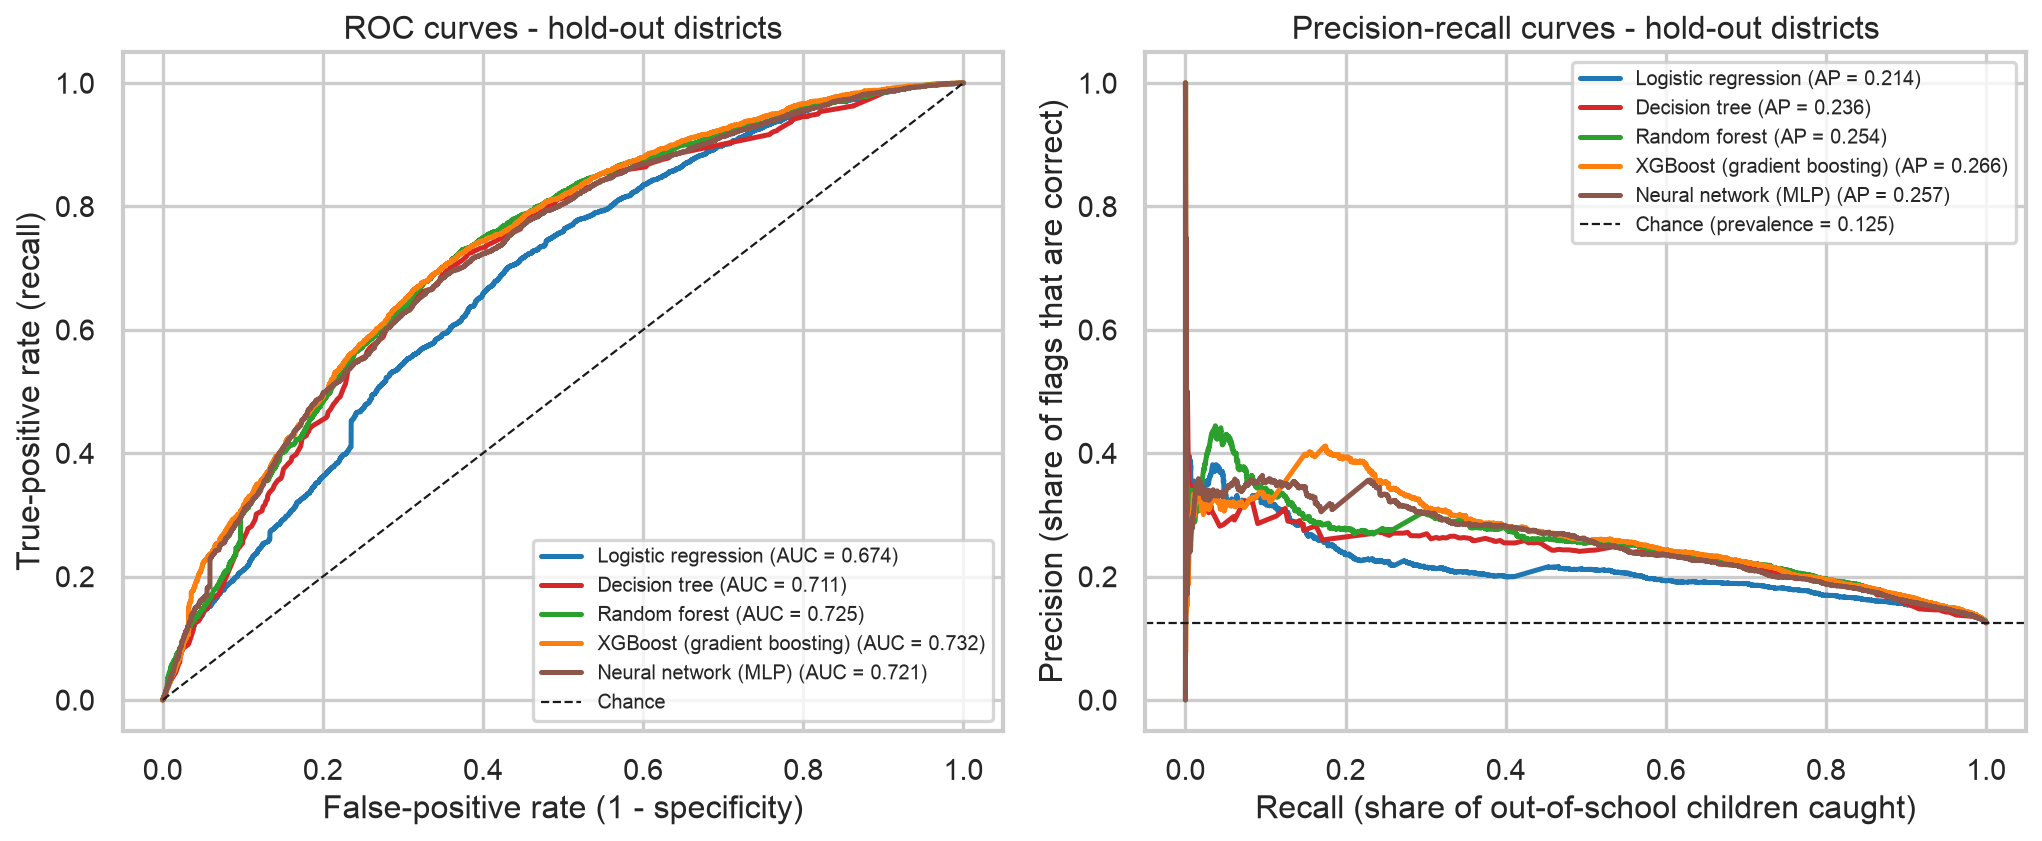

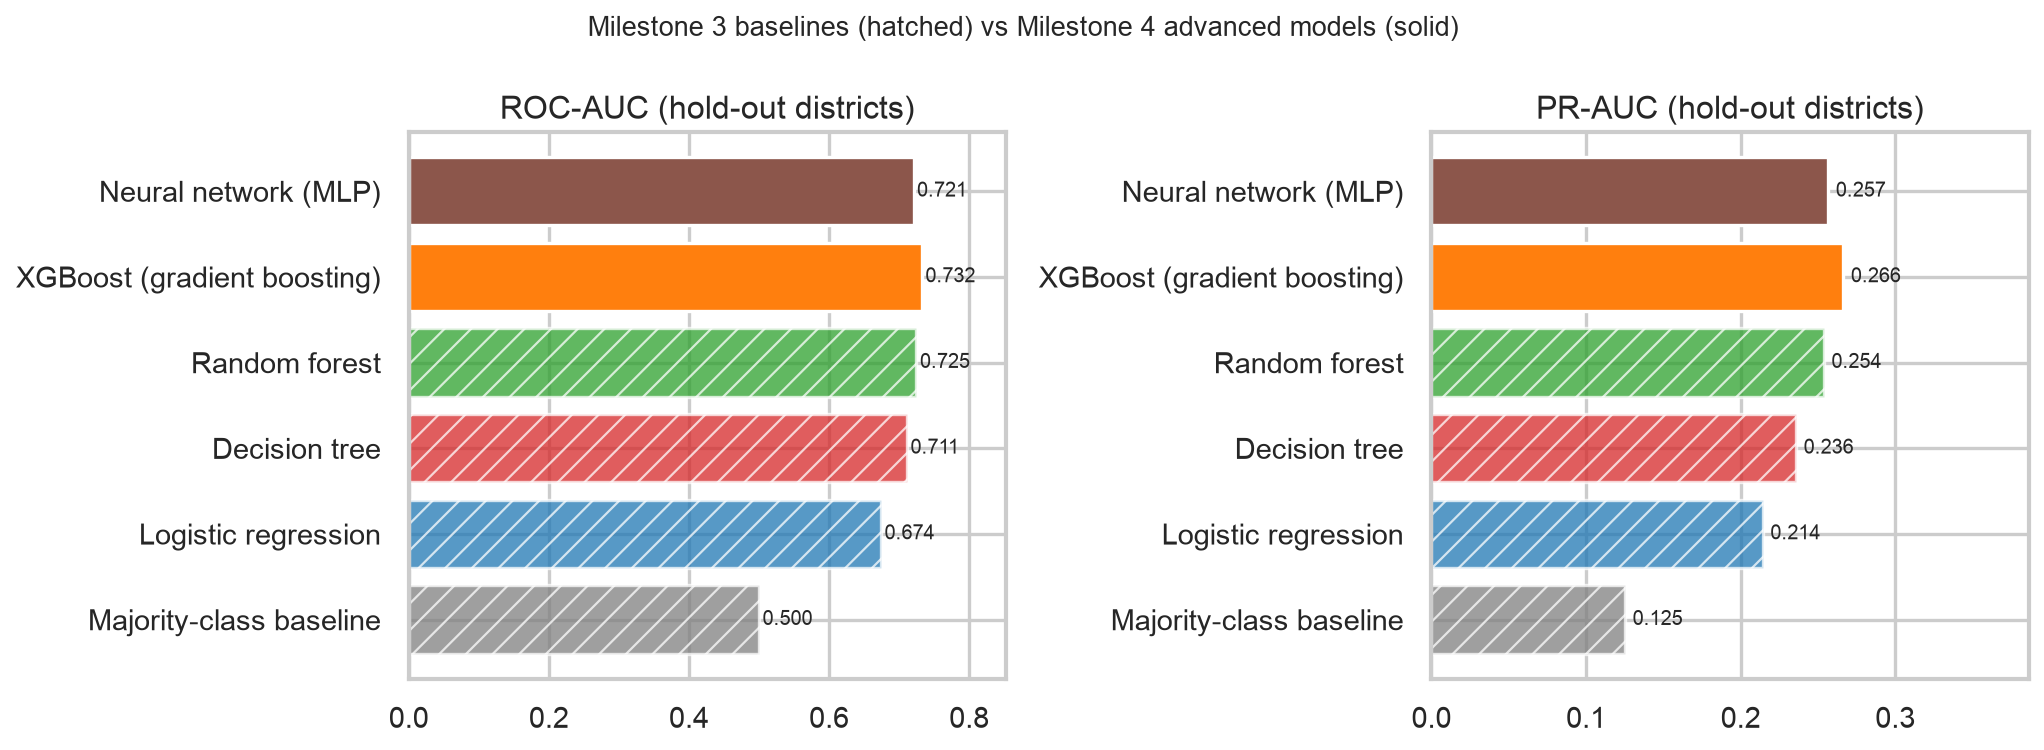

In [9]:
# ROC / PR curves and the benchmark bars (hatched = Milestone 3 baselines)
display(Image(plots.roc_pr_curves(yte, {k: probas[k] for k in M.ALL_MODELS}, M.MODEL_NAMES, float(yte.mean()))))
display(Image(plots.benchmark_bars(holdout[~holdout.weighted].assign(model_name=lambda d: d.model.map(M.MODEL_NAMES)), M.MODEL_NAMES, ["naive", *M.ALL_MODELS])))

### 4.1 Cost-tuned cut-offs on training out-of-fold predictions
As in Milestone 3: a false negative costs r false positives (r = 1, 3, 5, 10; 5 recommended). Each tuned model is re-fitted on the
grouped folds to obtain out-of-fold probabilities for every training child; the cost-minimising cut-off is chosen there and applied
once to the hold-out. The "oracle" column shows the hold-out's own optimum for transparency.

In [10]:
# Out-of-fold probabilities, cost sweeps, chosen cut-offs and hold-out performance at them
oof = {key: cross_val_predict(clone(fitted[key]), Xtr, ytr, groups=gtr, cv=make_inner_cv(), method="predict_proba", n_jobs=-1)[:, 1] for key in M.ALL_MODELS}
sweeps_oof, sweeps_ho, best_t = {}, {}, []
for key in M.ALL_MODELS:
    sw = ev.threshold_sweep(ytr, oof[key]); sh = ev.threshold_sweep(yte, probas[key]); sweeps_oof[key], sweeps_ho[key] = sw, sh
    bt = ev.best_thresholds(sw); bt.insert(0, "model", key)
    for i, r in bt.iterrows():
        c = ev.confusion(yte, (probas[key] >= r["threshold"]).astype(int)); m = ev.metrics_from_counts(c)
        bt.loc[i, "holdout_recall"], bt.loc[i, "holdout_precision"], bt.loc[i, "holdout_cost_per_1000"] = m["recall"], m["precision"], ev.expected_cost(c, r["cost_ratio_fn_to_fp"])
        col = f"cost_per_1000_ratio{int(r['cost_ratio_fn_to_fp'])}"; bt.loc[i, "holdout_oracle_threshold"] = sh.loc[sh[col].idxmin(), "threshold"]
    best_t.append(bt)
best_t = pd.concat(best_t, ignore_index=True)
rec_thr = {k: float(best_t[(best_t.model == k) & (best_t.cost_ratio_fn_to_fp == C.RECOMMENDED_COST_RATIO)].threshold.item()) for k in M.ALL_MODELS}
at5 = best_t[best_t.cost_ratio_fn_to_fp == C.RECOMMENDED_COST_RATIO].set_index("model")
rec_model = at5.holdout_cost_per_1000.idxmin()
# Mitigation focus: best ranker among models within 1% of the lowest cost (group cut-offs need a smooth score; a tree gives one score per leaf)
near = [k for k in M.ALL_MODELS if at5.loc[k, "holdout_cost_per_1000"] <= 1.01 * at5.holdout_cost_per_1000.min()]
focus = max(near, key=lambda k: ev.metrics(yte, probas[k])["roc_auc"])
print("cut-offs:", rec_thr, "| cheapest:", rec_model, "| mitigation focus:", focus, "| distinct hold-out scores:", {k: len(np.unique(probas[k].round(6))) for k in M.ALL_MODELS})
at5[["threshold", "recall", "precision", "holdout_recall", "holdout_precision", "holdout_cost_per_1000", "holdout_oracle_threshold"]]

cut-offs: {'logreg': 0.54, 'tree': 0.16, 'rf': 0.13, 'xgb': 0.53, 'mlp': 0.13} | cheapest: xgb | mitigation focus: xgb | distinct hold-out scores: {'logreg': 13283, 'tree': 221, 'rf': 12974, 'xgb': 13193, 'mlp': 12949}


,threshold,recall,precision,holdout_recall,holdout_precision,holdout_cost_per_1000,holdout_oracle_threshold
model,,,,,,,
logreg,0.54,0.642,0.263,0.568,0.201,552.282,0.57
tree,0.16,0.628,0.276,0.621,0.237,487.329,0.16
rf,0.13,0.722,0.258,0.709,0.220,496.156,0.18
xgb,0.53,0.649,0.267,0.645,0.235,484.531,0.58
mlp,0.13,0.696,0.255,0.689,0.218,503.998,0.23


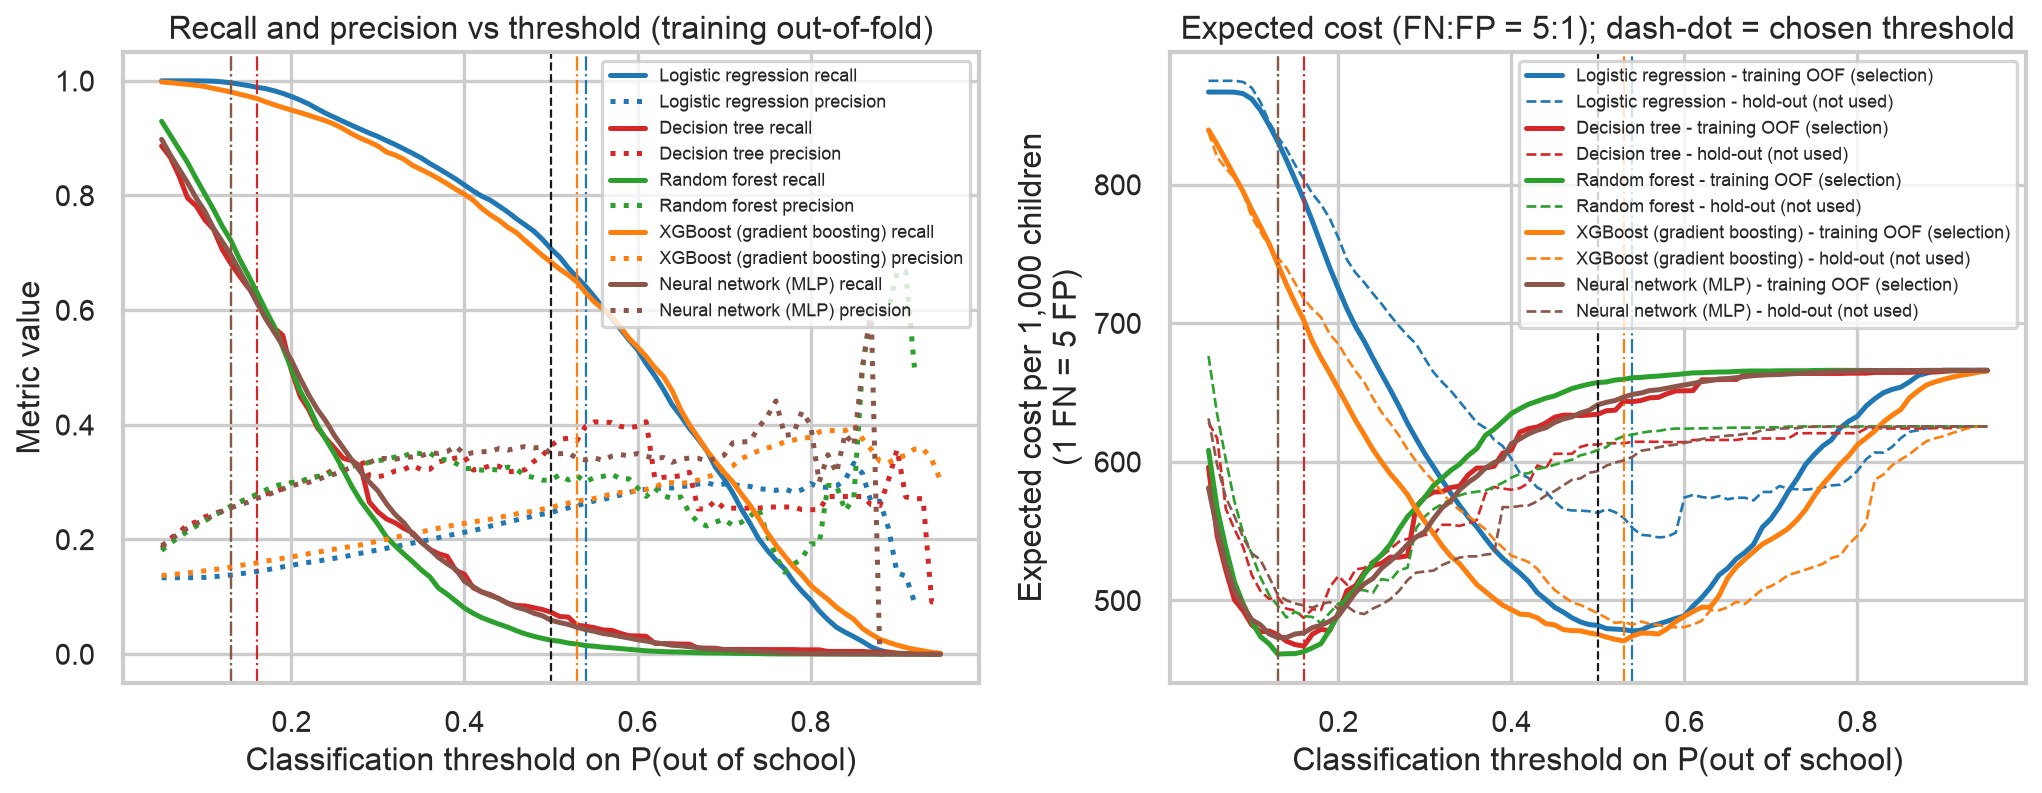

In [11]:
# Threshold / cost curves (solid = training OOF used for selection, dashed = hold-out)
display(Image(plots.threshold_curves(sweeps_oof, sweeps_ho, rec_thr, M.MODEL_NAMES, C.RECOMMENDED_COST_RATIO)))

## 5. Fairness metric functions and the audit
**Protected attributes**: gender (girls), area (rural), disability, legal identity (unregistered), poverty (bottom asset tercile),
province (each vs Punjab; Islamabad excluded - no hold-out rows). **Framing**: a positive prediction is a flag for outreach (help),
so the harm is a false negative and the disparate-impact concern is a group being *under-flagged* relative to need. Metrics are
nevertheless reported in the conventional direction (unprivileged relative to privileged). Functions are hand-coded in
`src/fairness.py` on top of the 2x2 confusion counts; see `F.disparity` for the definitions.

In [12]:
# Build the attribute arrays for train and test, including the poverty flag (tercile cut computed on training only)
poor_cut = float(np.quantile(df_tr["assets_n"], 1 / 3))
def attr_arrays(d):
    a = {k: d[k].to_numpy() for k in ("female", "urban", "any_disability", "bform")}
    a["poor"] = (d["assets_n"] <= poor_cut).astype(int).to_numpy(); a["province"] = province_of(d).to_numpy(); return a
A_tr, A_te = attr_arrays(df_tr), attr_arrays(df_te)
specs = {}
for k, s in C.PROTECTED.items():
    specs[k] = {"values": A_te[k], "priv": s["priv"], "unpriv": s["unpriv"], "label": s["label"], "priv_name": s["names"][s["priv"]], "unpriv_name": s["names"][s["unpriv"]]}
for prov in sorted(set(A_te["province"]) - {"Punjab"} - set(C.PROVINCE_ATTR["exclude"])):
    specs[f"province:{prov}"] = {"values": A_te["province"], "priv": "Punjab", "unpriv": prov, "label": f"Province: {prov} vs Punjab", "priv_name": "Punjab", "unpriv_name": prov}
print("poverty flag: assets_n <=", poor_cut, "| attributes:", list(specs))

poverty flag: assets_n <= 2.0 | attributes: ['female', 'urban', 'any_disability', 'bform', 'poor', 'province:Balochistan', 'province:Khyber Pakhtuknkhwa', 'province:Sindh']


In [13]:
# Worked example of the metrics for one model and one attribute (area), then the full audit with district-bootstrap CIs
yhat = (probas[focus] >= rec_thr[focus]).astype(int)
display(F.group_rates(yte, yhat, A_te["urban"], C.PROTECTED["urban"]["names"]))
d = F.disparity(yte, yhat, A_te["urban"], priv=1, unpriv=0)
print({k: round(v, 3) if isinstance(v, float) else v for k, v in d.items() if k in ("sel_priv", "sel_unpriv", "di_ratio", "di_within_band", "tpr_priv", "tpr_unpriv", "eopp_gap", "fpr_priv", "fpr_unpriv", "pe_gap", "eodds_diff")})
aud_rows = []
for key in M.ALL_MODELS:
    a = F.audit(yte, (probas[key] >= rec_thr[key]).astype(int), specs, clusters=gte, n_boot=1000); a.insert(0, "model", key); aud_rows.append(a)
aud = pd.concat(aud_rows, ignore_index=True)
aud[aud.model.isin([focus, rec_model])][["model", "label", "di_ratio", "di_within_band", "tpr_priv", "tpr_unpriv", "eopp_gap", "eopp_gap_ci_low", "eopp_gap_ci_high", "pe_gap", "eodds_diff", "small_group"]]

,level,group,n,positives,prevalence,selection_rate,tpr,fpr,fnr,precision,small
0,0,Rural,22350,2932,0.131,0.405,0.709,0.359,0.291,0.230,False
1,1,Urban,10166,1136,0.112,0.208,0.480,0.173,0.520,0.258,False


{'sel_priv': 0.208, 'tpr_priv': 0.48, 'fpr_priv': 0.173, 'sel_unpriv': 0.405, 'tpr_unpriv': 0.709, 'fpr_unpriv': 0.359, 'di_ratio': 1.949, 'di_within_band': False, 'eopp_gap': 0.229, 'pe_gap': 0.185, 'eodds_diff': 0.229}


,model,label,di_ratio,di_within_band,tpr_priv,tpr_unpriv,eopp_gap,eopp_gap_ci_low,eopp_gap_ci_high,pe_gap,eodds_diff,small_group
24,xgb,Gender,1.440,False,0.614,0.688,0.075,-0.024,0.175,0.127,0.127,False
25,xgb,Area,1.949,False,0.480,0.709,0.229,0.113,0.370,0.185,0.229,False
26,xgb,Disability,0.751,False,0.656,0.539,-0.117,-0.273,0.040,-0.078,0.117,False
27,xgb,Legal identity,1.900,False,0.523,0.731,0.209,0.088,0.316,0.197,0.209,False
28,xgb,Poverty,2.652,False,0.486,0.761,0.275,0.142,0.430,0.324,0.324,False
29,xgb,Province: Balochistan vs Punjab,2.964,False,0.520,0.884,0.364,0.250,0.550,0.481,0.481,False
30,xgb,Province: Khyber Pakhtuknkhwa vs Punjab,1.327,False,0.520,0.680,0.160,-0.078,0.397,0.050,0.160,False
31,xgb,Province: Sindh vs Punjab,0.522,False,0.520,0.450,-0.070,-0.447,0.152,-0.155,0.155,False


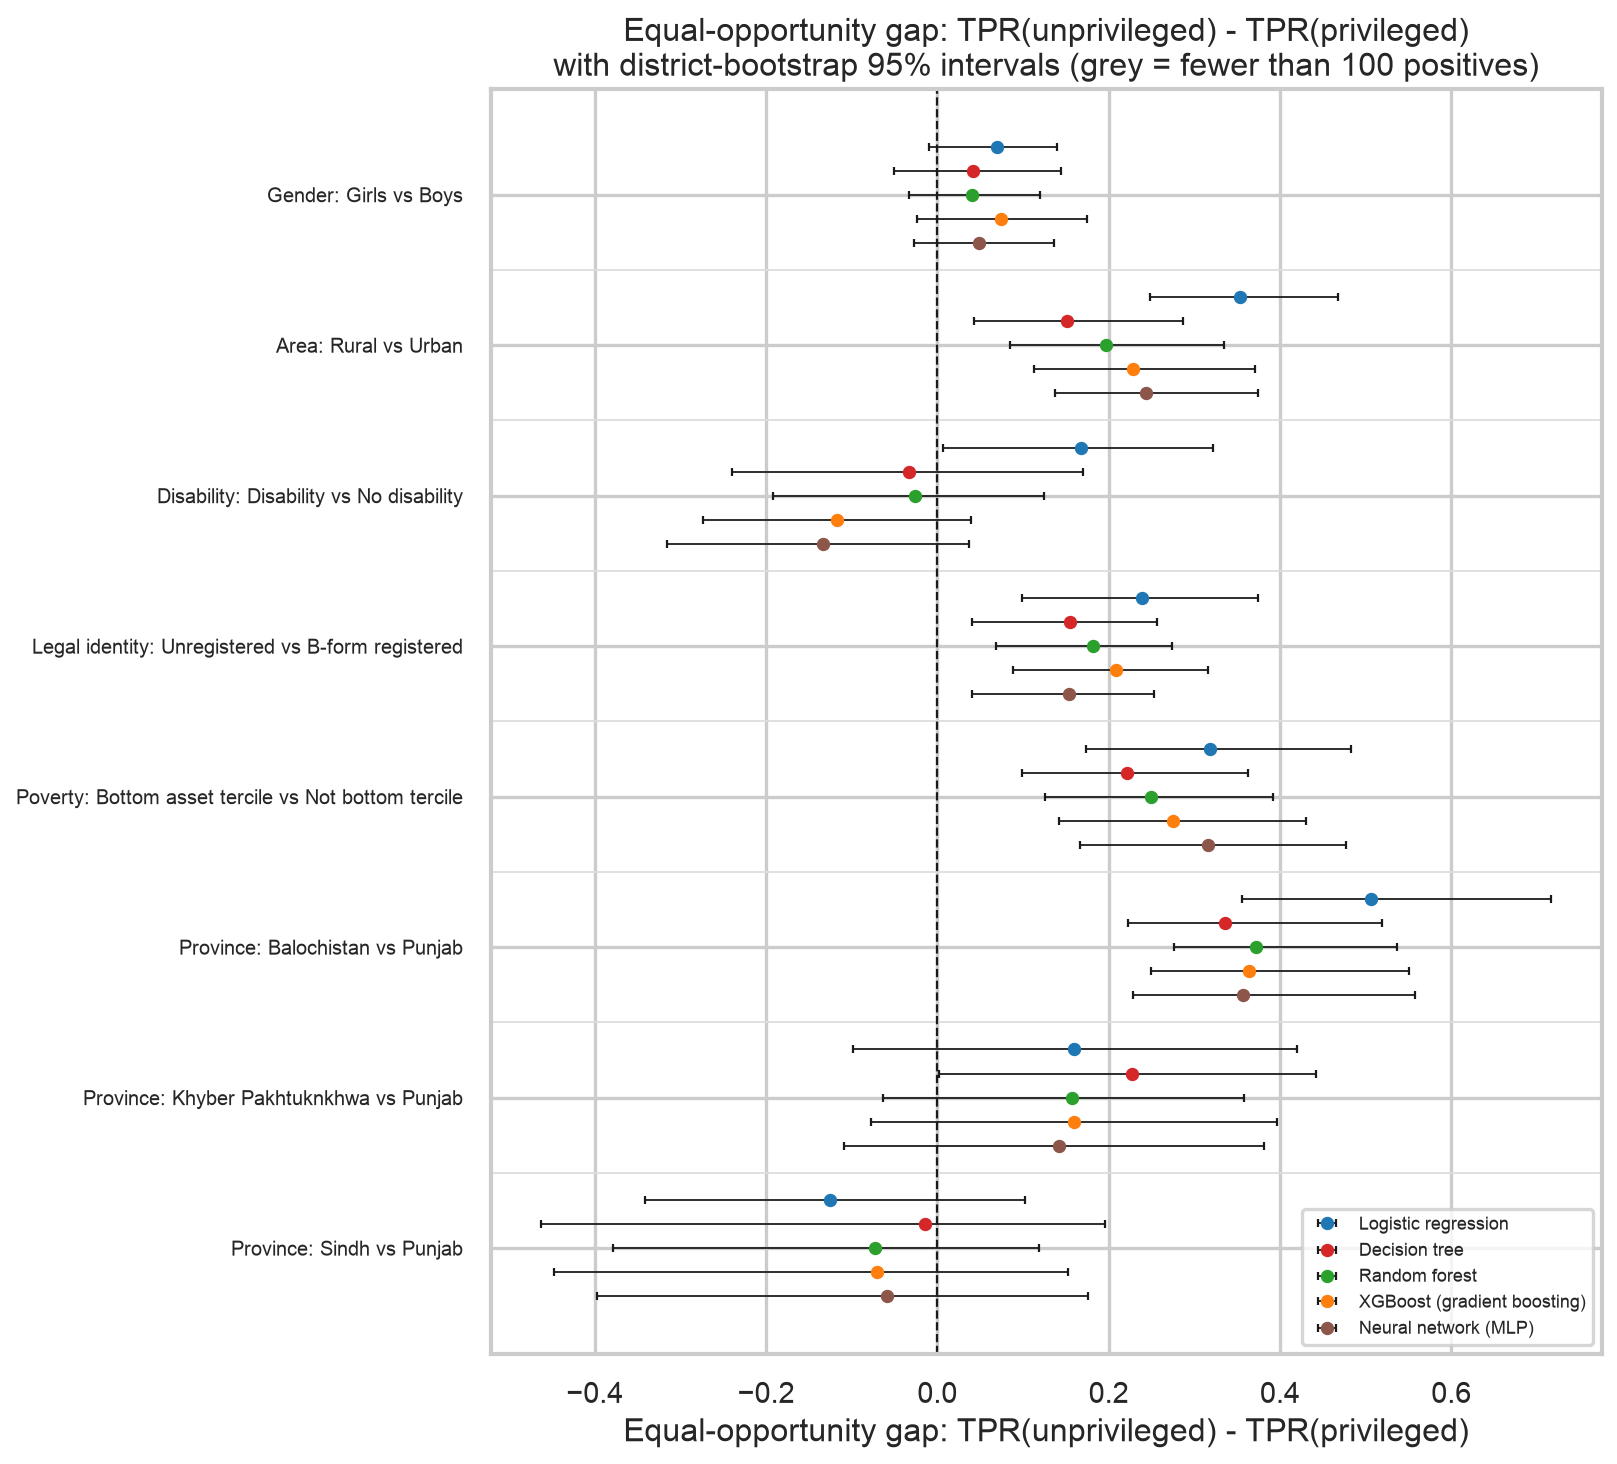

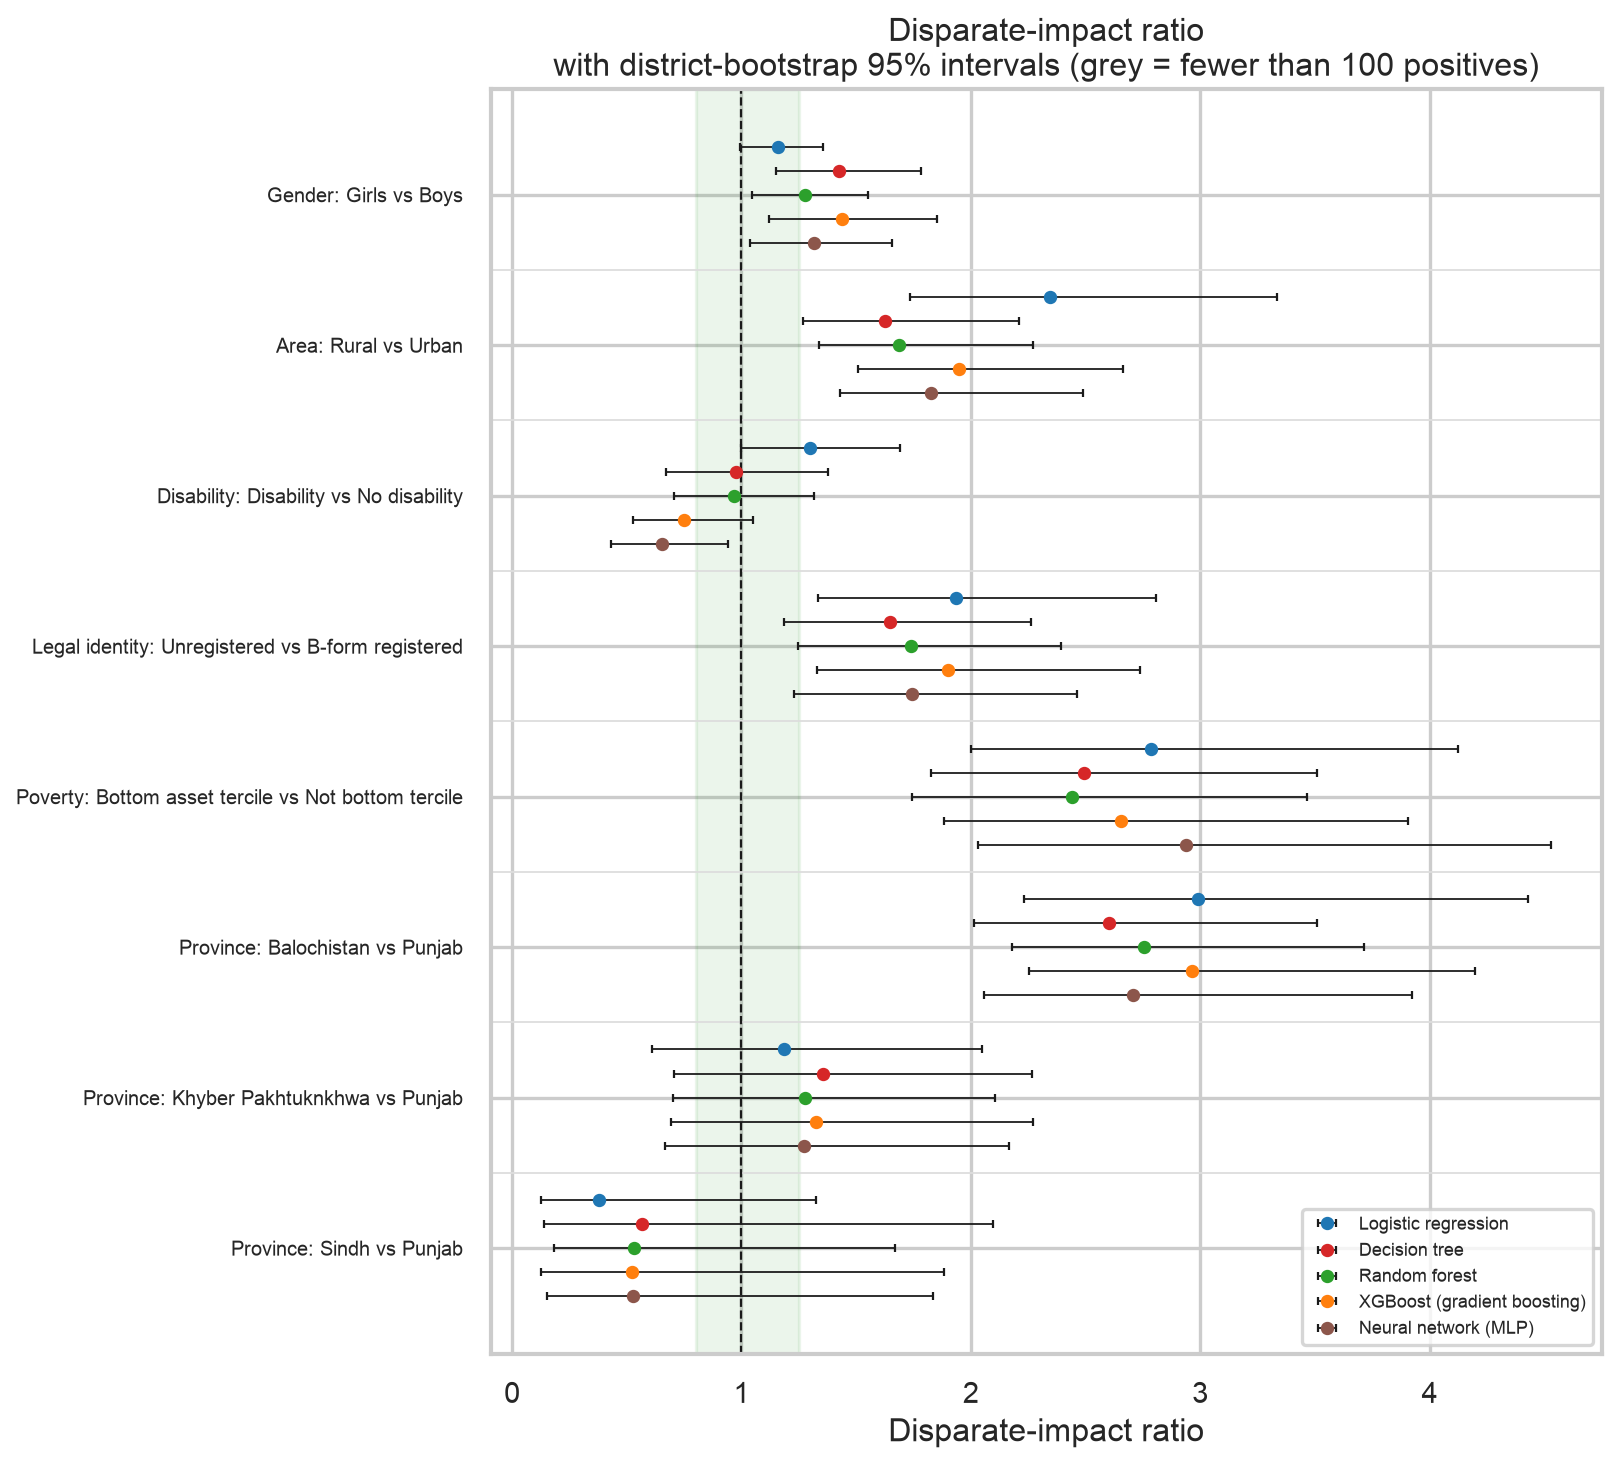

In [14]:
# Forest plots of the equal-opportunity gap and the disparate-impact ratio across all models and attributes
display(Image(plots.disparity_forest(aud, "eopp_gap", "Equal-opportunity gap: TPR(unprivileged) - TPR(privileged)", "fig11b_eopp_gap_forest", 0.0, M.MODEL_NAMES)))
display(Image(plots.disparity_forest(aud, "di_ratio", "Disparate-impact ratio", "fig11c_di_ratio_forest", 1.0, M.MODEL_NAMES)))

In [15]:
# Did the advanced models fix, preserve or worsen the Milestone 3 recall gaps? (M3 logistic regression as the reference)
m3 = pd.DataFrame(C.M3["subgroups_logreg"])
def m3_recall(var, lvl):
    r = m3[(m3.variable == var) & (m3.level.astype(str) == str(lvl))]; return float(r.recall.iloc[0]) if len(r) else np.nan
rows = []
for k in ("female", "urban", "any_disability", "bform", "province:Sindh", "province:Balochistan"):
    s = specs[k]; var = "province" if k.startswith("province:") else k
    g3 = m3_recall(var, s["unpriv"]) - m3_recall(var, s["priv"]); row = {"attribute": k, "m3_gap": g3}
    for key in M.ALL_MODELS:
        g = float(aud[(aud.model == key) & (aud.attribute == k)].eopp_gap.iloc[0]); row[key] = g
        row[f"{key}_verdict"] = "reduced" if abs(g) < abs(g3) - 0.05 else ("worsened" if abs(g) > abs(g3) + 0.05 else "preserved")
    rows.append(row)
pd.DataFrame(rows)

,attribute,m3_gap,logreg,logreg_verdict,tree,tree_verdict,rf,rf_verdict,xgb,xgb_verdict,mlp,mlp_verdict
0,female,0.070,0.070,preserved,0.041,preserved,0.040,preserved,0.075,preserved,0.049,preserved
1,urban,0.353,0.353,preserved,0.152,reduced,0.197,reduced,0.229,reduced,0.244,reduced
2,any_disability,0.168,0.168,preserved,-0.033,reduced,-0.027,reduced,-0.117,reduced,-0.133,preserved
3,bform,0.239,0.239,preserved,0.155,reduced,0.182,reduced,0.209,preserved,0.154,reduced
4,province:Sindh,-0.125,-0.125,preserved,-0.014,reduced,-0.073,reduced,-0.070,reduced,-0.058,reduced
5,province:Balochistan,0.507,0.507,preserved,0.336,reduced,0.371,reduced,0.364,reduced,0.357,reduced


## 6. Mitigation and asymmetric threshold optimisation
**Post-processing (main)**: a cut-off per group, chosen on training OOF predictions to minimise expected cost (1 FN = 5 FP) subject to
|TPR gap| <= 0.05, applied once to the hold-out. **Pre-processing**: Kamiran-Calders reweighing, model re-trained with sample weights,
single cut-off re-chosen on OOF. **Policy knob**: a missed girl / missed child with a disability costs 1.5x.

In [16]:
# Group-specific cut-offs for the mitigation-focus model (fine 0.0025 grid), before/after on the hold-out
rows = []
for k in C.PROTECTED:
    s = specs[k]; g = F.group_thresholds(ytr, oof[focus], A_tr[k], C.RECOMMENDED_COST_RATIO, C.RECOMMENDED_TPR_GAP, grid=F.FINE_GRID)
    yb = (probas[focus] >= rec_thr[focus]).astype(int); ya = F.apply_group_thresholds(probas[focus], A_te[k], g["thresholds"])
    db, da = F.disparity(yte, yb, A_te[k], s["priv"], s["unpriv"]), F.disparity(yte, ya, A_te[k], s["priv"], s["unpriv"])
    cb, ca = ev.confusion(yte, yb), ev.confusion(yte, ya)
    rows.append({"attribute": k, "thresholds": {str(a): b for a, b in g["thresholds"].items()}, "feasible_oof": g["feasible"],
                 "tpr_priv_before": db["tpr_priv"], "tpr_unpriv_before": db["tpr_unpriv"], "tpr_priv_after": da["tpr_priv"], "tpr_unpriv_after": da["tpr_unpriv"],
                 "eopp_gap_before": db["eopp_gap"], "eopp_gap_after": da["eopp_gap"], "fpr_unpriv_before": db["fpr_unpriv"], "fpr_unpriv_after": da["fpr_unpriv"],
                 "cost_before": ev.expected_cost(cb, 5), "cost_after": ev.expected_cost(ca, 5),
                 "flagged_before": ev.per_1000(cb)["flagged_per_1000"], "flagged_after": ev.per_1000(ca)["flagged_per_1000"]})
ba = pd.DataFrame(rows); ba

,attribute,thresholds,feasible_oof,tpr_priv_before,tpr_unpriv_before,tpr_priv_after,tpr_unpriv_after,eopp_gap_before,eopp_gap_after,fpr_unpriv_before,fpr_unpriv_after,cost_before,cost_after,flagged_before,flagged_after
0,female,"{'1': 0.595, '0': 0.522}",True,0.614,0.688,0.628,0.603,0.075,-0.025,0.382,0.308,484.531,484.623,343.0,322.795
1,urban,"{'0': 0.522, '1': 0.452}",True,0.480,0.709,0.594,0.720,0.229,0.126,0.359,0.370,484.531,486.191,343.0,374.923
2,any_disability,"{'0': 0.522, '1': 0.567}",True,0.656,0.539,0.668,0.485,-0.117,-0.182,0.230,0.197,484.531,485.976,343.0,347.952
3,bform,"{'0': 0.537, '1': 0.455}",True,0.523,0.731,0.639,0.728,0.209,0.089,0.414,0.408,484.531,496.894,343.0,390.239
4,poor,"{'0': 0.467, '1': 0.57}",True,0.486,0.761,0.581,0.712,0.275,0.131,0.507,0.444,484.531,493.173,343.0,360.684


In [17]:
# Reweighing (pre-processing) for area, gender and legal identity on logistic regression and XGBoost
rows = []
for k in ("urban", "female", "bform"):
    s = specs[k]
    for key in ("logreg", "xgb"):
        wts = F.reweighing_weights(ytr, A_tr[k]); pipe = clone(fitted[key]).fit(Xtr, ytr, clf__sample_weight=wts)
        oof_w = cross_val_predict(clone(fitted[key]), Xtr, ytr, groups=gtr, cv=make_inner_cv(), method="predict_proba", n_jobs=-1, params={"clf__sample_weight": wts})[:, 1]
        thr_w = float(ev.best_thresholds(ev.threshold_sweep(ytr, oof_w)).set_index("cost_ratio_fn_to_fp").loc[5, "threshold"])
        p_w = pipe.predict_proba(Xte)[:, 1]
        db = F.disparity(yte, (probas[key] >= rec_thr[key]).astype(int), A_te[k], s["priv"], s["unpriv"]); da = F.disparity(yte, (p_w >= thr_w).astype(int), A_te[k], s["priv"], s["unpriv"])
        rows.append({"model": key, "attribute": k, "auc_before": ev.metrics(yte, probas[key])["roc_auc"], "auc_after": ev.metrics(yte, p_w)["roc_auc"],
                     "eopp_gap_before": db["eopp_gap"], "eopp_gap_after": da["eopp_gap"], "di_before": db["di_ratio"], "di_after": da["di_ratio"],
                     "cost_before": ev.expected_cost(ev.confusion(yte, (probas[key] >= rec_thr[key]).astype(int)), 5), "cost_after": ev.expected_cost(ev.confusion(yte, (p_w >= thr_w).astype(int)), 5)})
pd.DataFrame(rows)

,model,attribute,auc_before,auc_after,eopp_gap_before,eopp_gap_after,di_before,di_after,cost_before,cost_after
0,logreg,urban,0.674,0.676,0.353,1.173e-01,2.346,1.213,552.282,550.590
1,xgb,urban,0.732,0.734,0.229,8.085e-02,1.949,1.229,484.531,493.572
2,logreg,female,0.674,0.672,0.070,-1.026e-02,1.159,0.955,552.282,554.250
3,xgb,female,0.732,0.731,0.075,1.165e-02,1.440,1.247,484.531,482.808
4,logreg,bform,0.674,0.648,0.239,-1.218e-01,1.937,0.968,552.282,607.978
5,xgb,bform,0.732,0.717,0.209,2.232e-04,1.900,1.113,484.531,514.946


In [18]:
# Equity cost knob: a missed girl / missed child with a disability costs 1.5x (no gap constraint)
rows = []
for k, mult in C.GROUP_FN_MULTIPLIER.items():
    s = specs[k]; g = F.group_thresholds(ytr, oof[focus], A_tr[k], 5, 1.0, fn_multiplier={s["unpriv"]: mult, s["priv"]: 1.0}, grid=F.FINE_GRID)
    ya = F.apply_group_thresholds(probas[focus], A_te[k], g["thresholds"]); d = F.disparity(yte, ya, A_te[k], s["priv"], s["unpriv"])
    rows.append({"attribute": k, "thresholds": {str(a): b for a, b in g["thresholds"].items()}, "tpr_priv": d["tpr_priv"], "tpr_unpriv": d["tpr_unpriv"], "eopp_gap": d["eopp_gap"],
                 "cost_standard": ev.expected_cost(ev.confusion(yte, ya), 5)})
pd.DataFrame(rows)

,attribute,thresholds,tpr_priv,tpr_unpriv,eopp_gap,cost_standard
0,female,"{'1': 0.422, '0': 0.532}",0.611,0.796,0.185,493.542
1,any_disability,"{'0': 0.522, '1': 0.387}",0.668,0.788,0.121,490.897


## 7. Fairness-accuracy Pareto frontier
For each allowed TPR gap the cost-minimising group cut-offs are found on training OOF and then scored on the hold-out; filled points
are non-dominated (no other point is both fairer and cheaper), the star is the single group-blind cut-off.

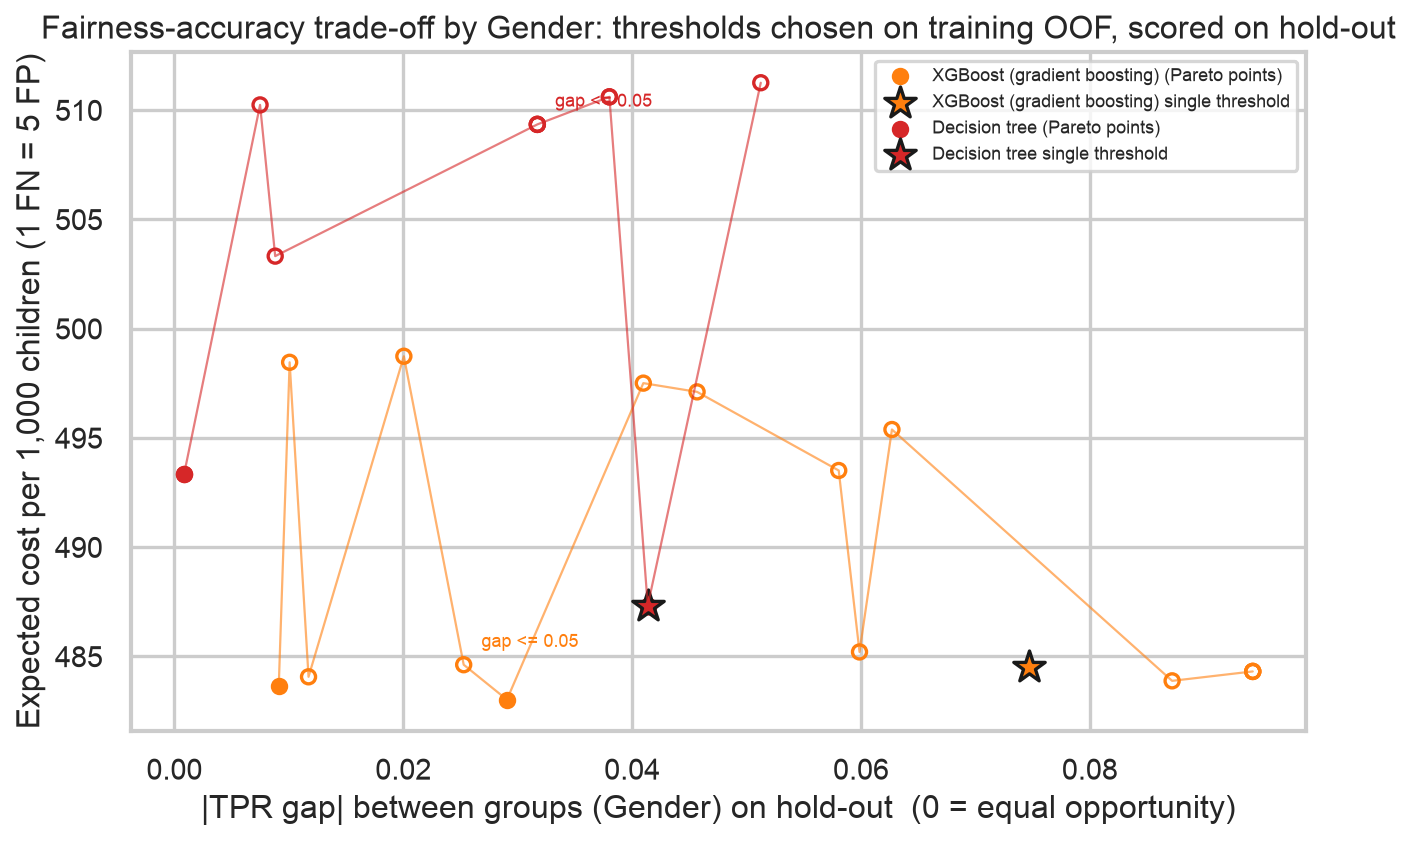

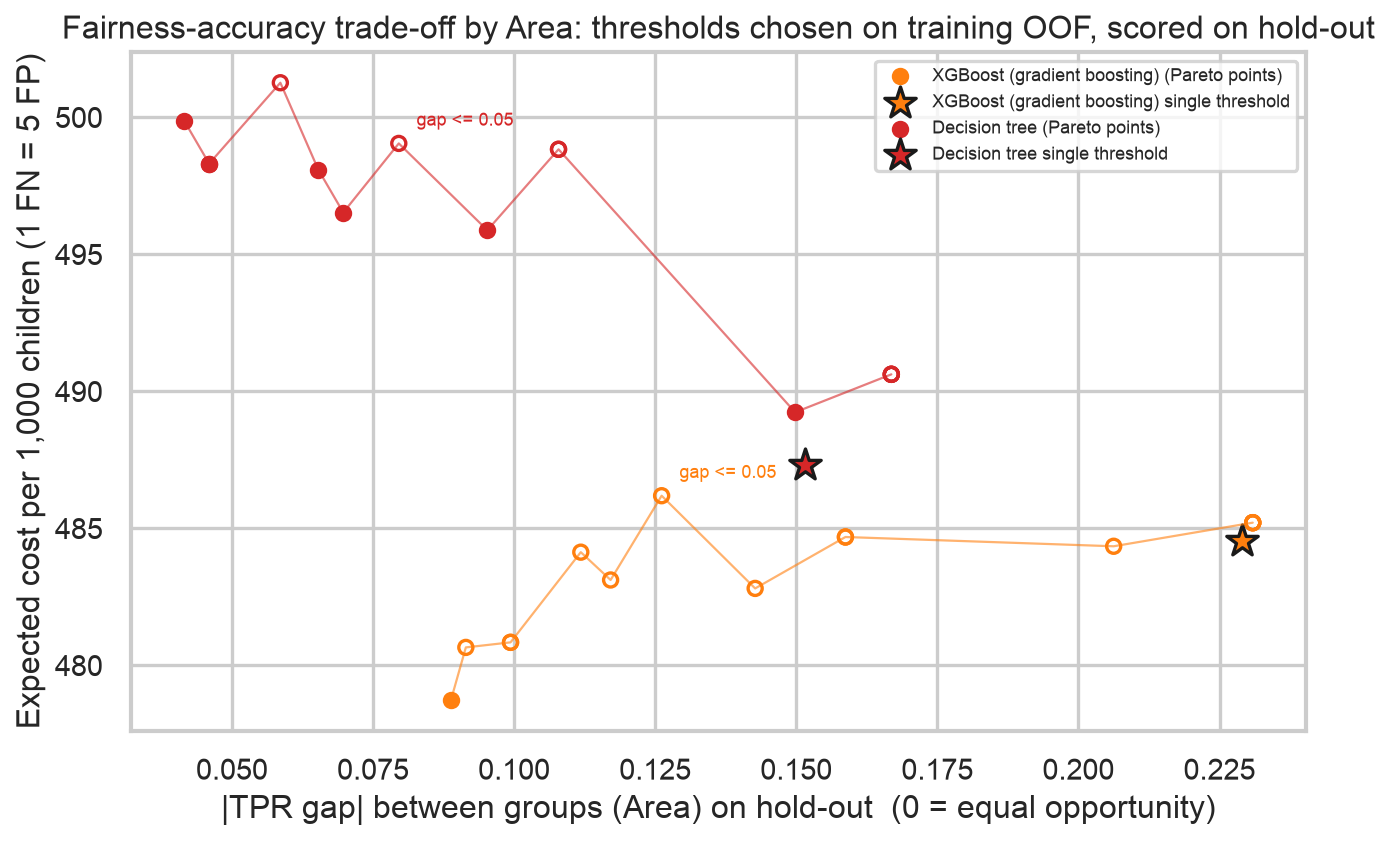

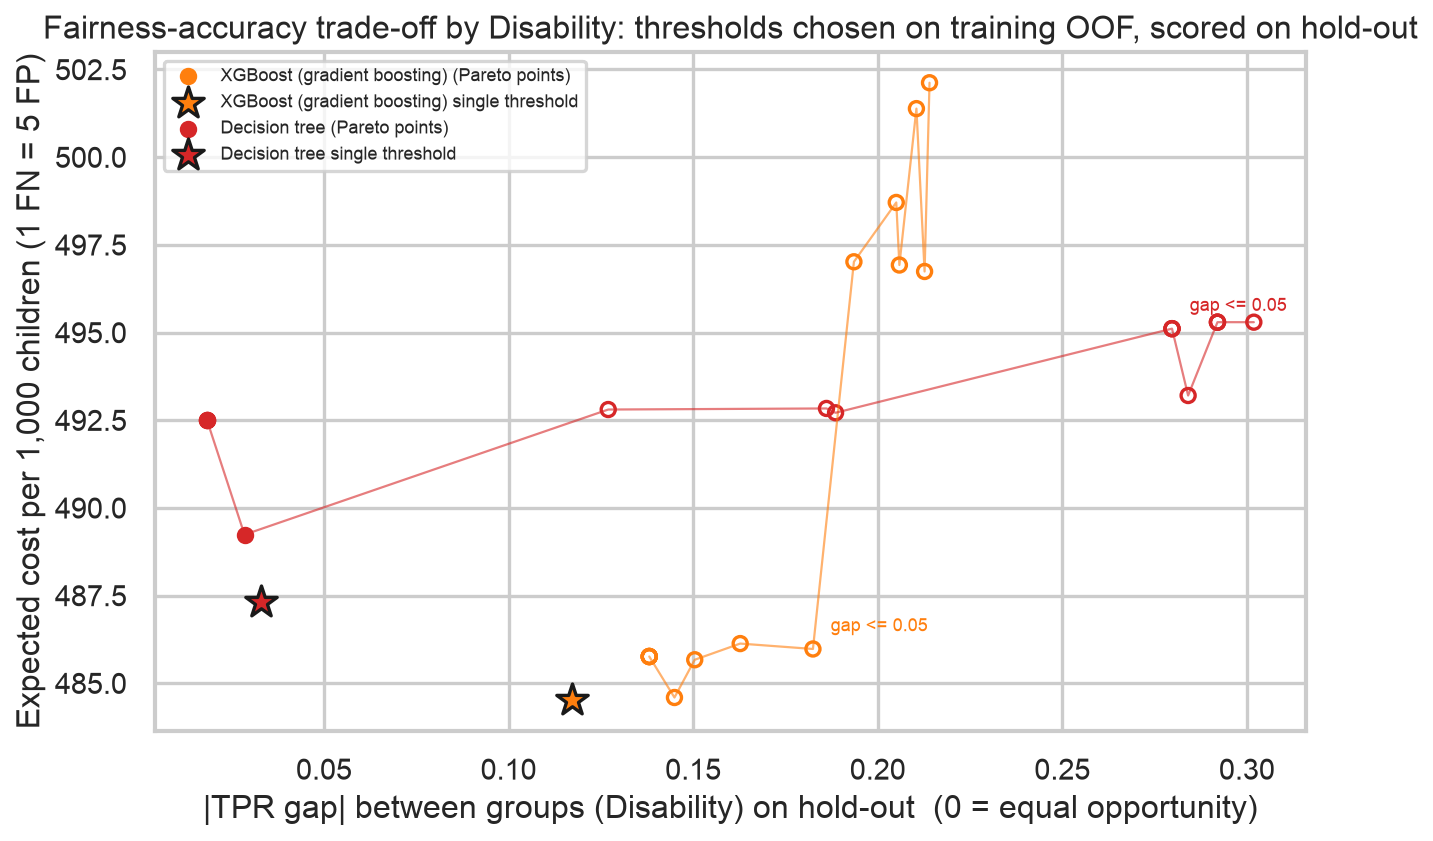

,max_tpr_gap,oof_tpr_gap,holdout_abs_gap,holdout_cost_per_1000,holdout_recall,pareto,point
0,0.005,0.003,0.089,478.749,0.630,True,group thresholds
1,0.010,0.008,0.091,480.656,0.635,False,group thresholds
2,0.015,0.014,0.099,480.840,0.633,False,group thresholds
3,0.020,0.014,0.099,480.840,0.633,False,group thresholds
4,0.030,0.029,0.112,484.131,0.675,False,group thresholds
5,0.040,0.040,0.117,483.116,0.673,False,group thresholds
6,0.050,0.043,0.126,486.191,0.685,False,group thresholds
7,0.060,0.060,0.143,482.808,0.669,False,group thresholds
8,0.080,0.074,0.159,484.684,0.676,False,group thresholds
9,0.100,0.074,0.159,484.684,0.676,False,group thresholds


In [19]:
# Frontiers for gender, area and disability (recommended model and XGBoost)
frontiers = {a: {} for a in C.PARETO_ATTRS}
for key in dict.fromkeys([focus, rec_model, "tree"]):   # Milestone 3 tree kept as a contrast
    for k in C.PARETO_ATTRS:
        s = specs[k]
        frontiers[k][key] = F.pareto_frontier(ytr, oof[key], A_tr[k], yte, probas[key], A_te[k], s["priv"], s["unpriv"], 5, single_threshold=rec_thr[key])
for k in C.PARETO_ATTRS:
    display(Image(plots.pareto_plot(frontiers[k], C.PROTECTED[k]["label"], f"fig12_pareto_{k}", M.MODEL_NAMES, C.RECOMMENDED_TPR_GAP)))
frontiers["urban"][focus][["max_tpr_gap", "oof_tpr_gap", "holdout_abs_gap", "holdout_cost_per_1000", "holdout_recall", "pareto", "point"]]

## 8. Export
`src/run_all.py` is the authoritative exporter (it writes every t*.csv, fig*.png and results.json, and `src/make_report.py` builds
the Word report from them). The cell below writes the notebook's own copies of the main tables so the two can be diffed.

In [20]:
# Write the notebook's tables next to the pipeline's (suffix _nb) and list the figures produced
aud.to_csv(C.TABLES_DIR / "nb_fairness_audit.csv", index=False); ba.to_csv(C.TABLES_DIR / "nb_mitigation_before_after.csv", index=False)
best_t.to_csv(C.TABLES_DIR / "nb_cost_thresholds.csv", index=False)
print(sorted(p.name for p in C.FIGURES_DIR.glob("*.png")))

['fig11_fairness_any_disability.png', 'fig11_fairness_bform.png', 'fig11_fairness_female.png', 'fig11_fairness_poor.png', 'fig11_fairness_province.png', 'fig11_fairness_urban.png', 'fig11b_eopp_gap_forest.png', 'fig11c_di_ratio_forest.png', 'fig12_pareto_any_disability.png', 'fig12_pareto_female.png', 'fig12_pareto_urban.png', 'fig13_before_after.png', 'fig14_benchmark.png', 'fig15_xgb_importance.png', 'fig1_roc_pr_curves.png', 'fig2_confusion_matrices_default.png', 'fig2_confusion_matrices_recommended.png', 'fig3_threshold_cost_curves.png']


In [21]:
# Environment for reproducibility
import sklearn, xgboost, platform
print("python", platform.python_version(), "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

python 3.13.5 | pandas 3.1.1 | scikit-learn 1.9.1 | xgboost 3.4.1
